In [24]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/aliraza0086/ai-animal-detection/ALIRAZA AI ANIMAL  DECTION/LIONS/images (2).jpg
/kaggle/input/datasets/aliraza0086/ai-animal-detection/ALIRAZA AI ANIMAL  DECTION/LIONS/images (3).jpg
/kaggle/input/datasets/aliraza0086/ai-animal-detection/ALIRAZA AI ANIMAL  DECTION/ELEPHENTS/images (5).jpg
/kaggle/input/datasets/aliraza0086/ai-animal-detection/ALIRAZA AI ANIMAL  DECTION/ELEPHENTS/images (6).jpg
/kaggle/input/datasets/aliraza0086/ai-animal-detection/ALIRAZA AI ANIMAL  DECTION/DOGS/images (1).jpg
/kaggle/input/datasets/aliraza0086/ai-animal-detection/ALIRAZA AI ANIMAL  DECTION/DOGS/images.jpg
/kaggle/input/datasets/aliraza0086/ai-animal-detection/ALIRAZA AI ANIMAL  DECTION/TIGURES/images (4).jpg
/kaggle/input/datasets/aliraza0086/ai-animal-detection/ALIRAZA AI ANIMAL  DECTION/TIGURES/download.jpg
/kaggle/input/datasets/aliraza0086/ai-animal-detection/ALIRAZA AI ANIMAL  DECTION/CATS/download (1).jpg
/kaggle/input/datasets/aliraza0086/ai-animal-detection/ALIRAZA AI AN

**Dataset Check Karne Ka Code**

In [25]:
import os

print("Available datasets:")

for dirname, _, filenames in os.walk("/kaggle/input"):
    level = dirname.replace("/kaggle/input", "").count(os.sep)

    if level <= 2:
        print(dirname)

Available datasets:
/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/aliraza0086


In [26]:
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.20,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.20,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

class_names = train_ds.class_names

print("Animal Classes:", class_names)
print("Total Classes:", len(class_names))

Found 10 files belonging to 5 classes.
Using 8 files for training.
Found 10 files belonging to 5 classes.
Using 2 files for validation.
Animal Classes: ['CATS', 'DOGS', 'ELEPHENTS', 'LIONS', 'TIGURES']
Total Classes: 5


In [27]:
import tensorflow as tf

# Pretrained MobileNetV2 model
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze pretrained layers
base_model.trainable = False

# Create our model
inputs = tf.keras.Input(shape=(224, 224, 3))

x = tf.keras.layers.RandomFlip("horizontal")(inputs)
x = tf.keras.layers.RandomRotation(0.1)(x)

x = tf.keras.applications.mobilenet_v2.preprocess_input(x)

x = base_model(x, training=False)

x = tf.keras.layers.GlobalAveragePooling2D()(x)

x = tf.keras.layers.Dropout(0.2)(x)

outputs = tf.keras.layers.Dense(
    len(class_names),
    activation="softmax"
)(x)

model = tf.keras.Model(inputs, outputs)

# Compile model
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Display model
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip_1 (RandomFlip)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_1               │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide_1 (TrueDivide)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract_1 (Subtract)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │         6,405 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,264,389 (8.64 MB)

 Trainable params: 6,405 (25.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

**AI Model Train Karein**

In [28]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 7s 7s/step - accuracy: 0.2500 - loss: 2.2675 - val_accuracy: 0.0000e+00 - val_loss: 1.7900
Epoch 2/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 334ms/step - accuracy: 0.1250 - loss: 2.0842 - val_accuracy: 0.0000e+00 - val_loss: 1.8050
Epoch 3/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 617ms/step - accuracy: 0.2500 - loss: 1.7063 - val_accuracy: 0.0000e+00 - val_loss: 1.8117
Epoch 4/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 342ms/step - accuracy: 0.5000 - loss: 1.2675 - val_accuracy: 0.0000e+00 - val_loss: 1.8249
Epoch 5/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 312ms/step - accuracy: 0.8750 - loss: 1.0576 - val_accuracy: 0.0000e+00 - val_loss: 1.8367
Epoch 6/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 383ms/step - accuracy: 0.7500 - loss: 0.9868 - val_accuracy: 0.0000e+00 - val_loss: 1.8434
Epoch 7/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 321ms/step - accuracy: 0.7500 - loss: 0.7391 - val_accuracy: 0.0000e+00 - val_loss: 1.8315
Epoch 8/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 319ms/step - accuracy: 0.6250 - loss: 1.0013 - val_acc

**Accuracy aur Loss Graph Banayein**

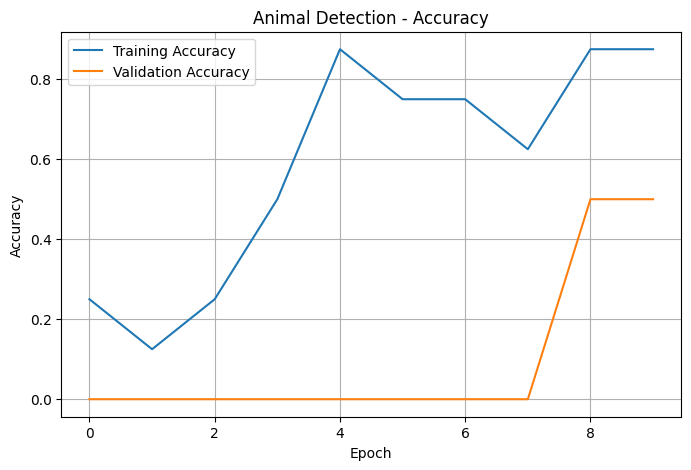

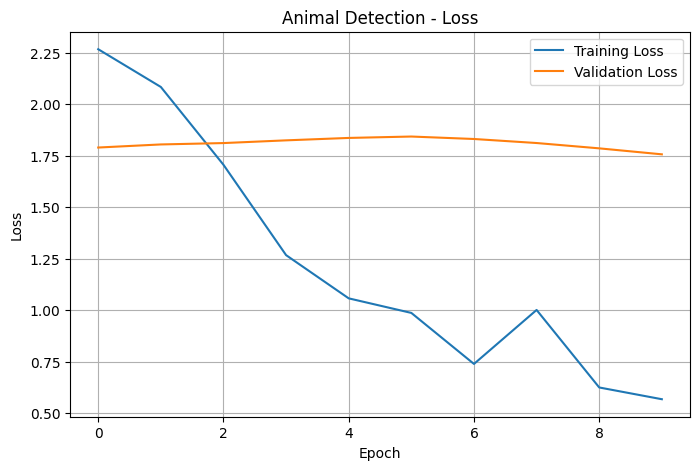

In [29]:
import matplotlib.pyplot as plt

# Accuracy Graph
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Animal Detection - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()


# Loss Graph
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Animal Detection - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

**Photo Upload Karke Animal Identify Karein**

In [30]:
import os
import json

# Save trained model
model.save("/kaggle/working/animal_detection_model.keras")

# Save class names
with open("/kaggle/working/animal_classes.json", "w") as f:
    json.dump(class_names, f)

print("Model saved successfully!")

print(os.listdir("/kaggle/working"))

Model saved successfully!
['animal_classes.json', 'animal_detection_model.keras', '.virtual_documents']


In [31]:
import tensorflow as tf
import numpy as np
import json
from PIL import Image
import matplotlib.pyplot as plt

model = tf.keras.models.load_model(
    "/kaggle/working/animal_detection_model.keras"
)

with open("/kaggle/working/animal_classes.json", "r") as f:
    class_names = json.load(f)

print("Model loaded successfully!")
print("Animal classes:", class_names)

Model loaded successfully!
Animal classes: ['CATS', 'DOGS', 'ELEPHENTS', 'LIONS', 'TIGURES']


In [32]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if file.lower().endswith((".jpg", ".jpeg", ".png", ".webp")):
            print(os.path.join(root, file))

/kaggle/input/datasets/aliraza0086/ai-animal-detection/ALIRAZA AI ANIMAL  DECTION/LIONS/images (2).jpg
/kaggle/input/datasets/aliraza0086/ai-animal-detection/ALIRAZA AI ANIMAL  DECTION/LIONS/images (3).jpg
/kaggle/input/datasets/aliraza0086/ai-animal-detection/ALIRAZA AI ANIMAL  DECTION/ELEPHENTS/images (5).jpg
/kaggle/input/datasets/aliraza0086/ai-animal-detection/ALIRAZA AI ANIMAL  DECTION/ELEPHENTS/images (6).jpg
/kaggle/input/datasets/aliraza0086/ai-animal-detection/ALIRAZA AI ANIMAL  DECTION/DOGS/images (1).jpg
/kaggle/input/datasets/aliraza0086/ai-animal-detection/ALIRAZA AI ANIMAL  DECTION/DOGS/images.jpg
/kaggle/input/datasets/aliraza0086/ai-animal-detection/ALIRAZA AI ANIMAL  DECTION/TIGURES/images (4).jpg
/kaggle/input/datasets/aliraza0086/ai-animal-detection/ALIRAZA AI ANIMAL  DECTION/TIGURES/download.jpg
/kaggle/input/datasets/aliraza0086/ai-animal-detection/ALIRAZA AI ANIMAL  DECTION/CATS/download (1).jpg
/kaggle/input/datasets/aliraza0086/ai-animal-detection/ALIRAZA AI AN

In [33]:
IMAGE_PATH = "/kaggle/input/datasets/aliraza0086/ai-animal-detection/ALIRAZA AI ANIMAL  DECTION/CATS/cat1.jpg"

Selected image: /kaggle/input/datasets/aliraza0086/ai-animal-detection/ALIRAZA AI ANIMAL  DECTION/CATS/images (7).jpg


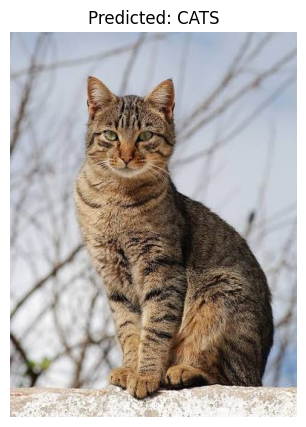

Predicted Animal: CATS
Confidence: 72.80%
Actual folder: CATS


In [34]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Dataset ka path
DATASET_PATH = "/kaggle/input/datasets/aliraza0086/ai-animal-detection/ALIRAZA AI ANIMAL  DECTION"

# Dataset se automatically ek image select karein
image_extensions = (".jpg", ".jpeg", ".png", ".webp")
image_paths = []

for root, dirs, files in os.walk(DATASET_PATH):
    for file in files:
        if file.lower().endswith(image_extensions):
            image_paths.append(os.path.join(root, file))

if not image_paths:
    print("Images nahi milin. Dataset path check karein.")
else:
    IMAGE_PATH = random.choice(image_paths)

    print("Selected image:", IMAGE_PATH)

    # Image load karein
    img = Image.open(IMAGE_PATH).convert("RGB")
    img_resized = img.resize((224, 224))

    # Prediction ke liye prepare karein
    img_array = np.array(img_resized, dtype=np.float32)
    img_array = np.expand_dims(img_array, axis=0)

    # AI prediction
    predictions = model.predict(img_array, verbose=0)

    index = np.argmax(predictions[0])
    predicted_animal = class_names[index]
    confidence = predictions[0][index] * 100

    # Image aur result show karein
    plt.figure(figsize=(5, 5))
    plt.imshow(img)
    plt.axis("off")
    plt.title(f"Predicted: {predicted_animal}")
    plt.show()

    print("Predicted Animal:", predicted_animal)
    print(f"Confidence: {confidence:.2f}%")
    print("Actual folder:", os.path.basename(os.path.dirname(IMAGE_PATH)))

In [35]:
import os
import json

# Save trained model
model.save("/kaggle/working/animal_detection_model.keras")

# Save class names
with open("/kaggle/working/animal_classes.json", "w") as f:
    json.dump(class_names, f)

print("Model saved successfully!")

print(os.listdir("/kaggle/working"))


Model saved successfully!
['animal_classes.json', 'animal_detection_model.keras', '.virtual_documents']
